In [1]:
!pip -q install nltk textblob wordcloud scikit-learn

In [2]:
import re
import nltk
import numpy as np
import matplotlib.pyplot as plt

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


In [3]:
text = """
Artificial intelligence is transforming the world through smart technologies.
Machine learning helps computers learn patterns from data and make predictions.
Deep learning uses neural networks to solve complex problems.
Natural language processing enables computers to understand human language.
These technologies support healthcare, education, transportation, and scientific research.
Responsible development is essential to make artificial intelligence useful and safe.
"""

# Convert to lowercase and remove punctuation
clean_text = re.sub(r'[^\w\s]', '', text.lower())

print("Original text:\n", text)
print("\nCleaned text:\n", clean_text)

Original text:
 
Artificial intelligence is transforming the world through smart technologies.
Machine learning helps computers learn patterns from data and make predictions.
Deep learning uses neural networks to solve complex problems.
Natural language processing enables computers to understand human language.
These technologies support healthcare, education, transportation, and scientific research.
Responsible development is essential to make artificial intelligence useful and safe.


Cleaned text:
 
artificial intelligence is transforming the world through smart technologies
machine learning helps computers learn patterns from data and make predictions
deep learning uses neural networks to solve complex problems
natural language processing enables computers to understand human language
these technologies support healthcare education transportation and scientific research
responsible development is essential to make artificial intelligence useful and safe



In [4]:
word_tokens = word_tokenize(text.lower())
sentence_tokens = sent_tokenize(text)

print("Word tokens:\n", word_tokens)
print("\nSentence tokens:")
for sentence in sentence_tokens:
    print(sentence)

Word tokens:
 ['artificial', 'intelligence', 'is', 'transforming', 'the', 'world', 'through', 'smart', 'technologies', '.', 'machine', 'learning', 'helps', 'computers', 'learn', 'patterns', 'from', 'data', 'and', 'make', 'predictions', '.', 'deep', 'learning', 'uses', 'neural', 'networks', 'to', 'solve', 'complex', 'problems', '.', 'natural', 'language', 'processing', 'enables', 'computers', 'to', 'understand', 'human', 'language', '.', 'these', 'technologies', 'support', 'healthcare', ',', 'education', ',', 'transportation', ',', 'and', 'scientific', 'research', '.', 'responsible', 'development', 'is', 'essential', 'to', 'make', 'artificial', 'intelligence', 'useful', 'and', 'safe', '.']

Sentence tokens:

Artificial intelligence is transforming the world through smart technologies.
Machine learning helps computers learn patterns from data and make predictions.
Deep learning uses neural networks to solve complex problems.
Natural language processing enables computers to understand hum

In [5]:
sample = "AI learns quickly. It solves problems!"

split_tokens = sample.split()
nltk_tokens = word_tokenize(sample)

print("Python split():", split_tokens)
print("NLTK word_tokenize():", nltk_tokens)

Python split(): ['AI', 'learns', 'quickly.', 'It', 'solves', 'problems!']
NLTK word_tokenize(): ['AI', 'learns', 'quickly', '.', 'It', 'solves', 'problems', '!']


In [6]:
filtered_words = [
    word for word in word_tokenize(clean_text)
    if word not in stop_words
]

print("Words after stopword removal:\n", filtered_words)

Words after stopword removal:
 ['artificial', 'intelligence', 'transforming', 'world', 'smart', 'technologies', 'machine', 'learning', 'helps', 'computers', 'learn', 'patterns', 'data', 'make', 'predictions', 'deep', 'learning', 'uses', 'neural', 'networks', 'solve', 'complex', 'problems', 'natural', 'language', 'processing', 'enables', 'computers', 'understand', 'human', 'language', 'technologies', 'support', 'healthcare', 'education', 'transportation', 'scientific', 'research', 'responsible', 'development', 'essential', 'make', 'artificial', 'intelligence', 'useful', 'safe']


Word frequencies:
artificial: 2
intelligence: 2
technologies: 2
learning: 2
computers: 2
make: 2
language: 2
transforming: 1
world: 1
smart: 1
machine: 1
helps: 1
learn: 1
patterns: 1
data: 1
predictions: 1
deep: 1
uses: 1
neural: 1
networks: 1
solve: 1
complex: 1
problems: 1
natural: 1
processing: 1
enables: 1
understand: 1
human: 1
support: 1
healthcare: 1
education: 1
transportation: 1
scientific: 1
research: 1
responsible: 1
development: 1
essential: 1
useful: 1
safe: 1


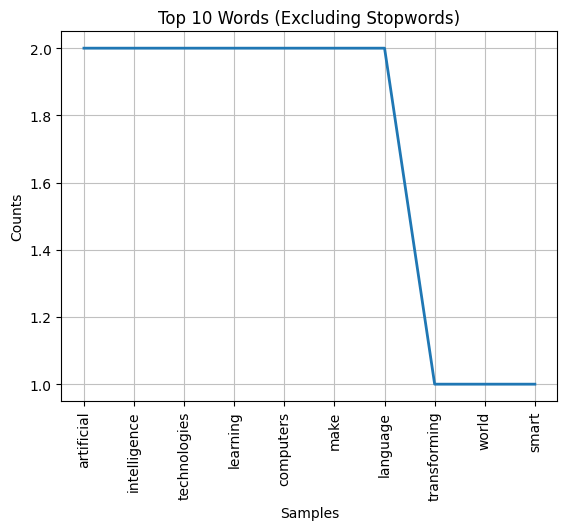

In [7]:
freq_dist = FreqDist(filtered_words)

print("Word frequencies:")
for word, frequency in freq_dist.most_common():
    print(f"{word}: {frequency}")

freq_dist.plot(10, title="Top 10 Words (Excluding Stopwords)")
plt.show()

In [8]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

alphabetic_words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

filtered_words_q2 = [
    word for word in alphabetic_words
    if word not in stop_words
]

print("Alphabetic words:\n", alphabetic_words)
print("\nAfter stopword removal:\n", filtered_words_q2)

Alphabetic words:
 ['artificial', 'intelligence', 'is', 'transforming', 'the', 'world', 'through', 'smart', 'technologies', 'machine', 'learning', 'helps', 'computers', 'learn', 'patterns', 'from', 'data', 'and', 'make', 'predictions', 'deep', 'learning', 'uses', 'neural', 'networks', 'to', 'solve', 'complex', 'problems', 'natural', 'language', 'processing', 'enables', 'computers', 'to', 'understand', 'human', 'language', 'these', 'technologies', 'support', 'healthcare', 'education', 'transportation', 'and', 'scientific', 'research', 'responsible', 'development', 'is', 'essential', 'to', 'make', 'artificial', 'intelligence', 'useful', 'and', 'safe']

After stopword removal:
 ['artificial', 'intelligence', 'transforming', 'world', 'smart', 'technologies', 'machine', 'learning', 'helps', 'computers', 'learn', 'patterns', 'data', 'make', 'predictions', 'deep', 'learning', 'uses', 'neural', 'networks', 'solve', 'complex', 'problems', 'natural', 'language', 'processing', 'enables', 'compute

In [9]:
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_words = [stemmer.stem(word) for word in filtered_words_q2]
lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_words_q2]

print(f"{'Original':<20}{'Stemmed':<20}{'Lemmatized'}")
print("-" * 55)

for original, stem, lemma in zip(
    filtered_words_q2, stemmed_words, lemmatized_words
):
    print(f"{original:<20}{stem:<20}{lemma}")

Original            Stemmed             Lemmatized
-------------------------------------------------------
artificial          artifici            artificial
intelligence        intellig            intelligence
transforming        transform           transforming
world               world               world
smart               smart               smart
technologies        technolog           technology
machine             machin              machine
learning            learn               learning
helps               help                help
computers           comput              computer
learn               learn               learn
patterns            pattern             pattern
data                data                data
make                make                make
predictions         predict             prediction
deep                deep                deep
learning            learn               learning
uses                use                 us
neural              neural    

In [10]:
comparison = list(zip(filtered_words_q2, stemmed_words, lemmatized_words))
print("Original -> Stemmed -> Lemmatized")
for original, stem, lemma in comparison:
    print(f"{original} -> {stem} -> {lemma}")

Original -> Stemmed -> Lemmatized
artificial -> artifici -> artificial
intelligence -> intellig -> intelligence
transforming -> transform -> transforming
world -> world -> world
smart -> smart -> smart
technologies -> technolog -> technology
machine -> machin -> machine
learning -> learn -> learning
helps -> help -> help
computers -> comput -> computer
learn -> learn -> learn
patterns -> pattern -> pattern
data -> data -> data
make -> make -> make
predictions -> predict -> prediction
deep -> deep -> deep
learning -> learn -> learning
uses -> use -> us
neural -> neural -> neural
networks -> network -> network
solve -> solv -> solve
complex -> complex -> complex
problems -> problem -> problem
natural -> natur -> natural
language -> languag -> language
processing -> process -> processing
enables -> enabl -> enables
computers -> comput -> computer
understand -> understand -> understand
human -> human -> human
language -> languag -> language
technologies -> technolog -> technology
support -

In [11]:
texts = [
    "Artificial intelligence improves healthcare through medical data analysis.",
    "Machine learning helps doctors predict diseases using patient data.",
    "Blockchain technology secures digital transactions and financial records."
]

for i, document in enumerate(texts, start=1):
    print(f"Text {i}: {document}")

Text 1: Artificial intelligence improves healthcare through medical data analysis.
Text 2: Machine learning helps doctors predict diseases using patient data.
Text 3: Blockchain technology secures digital transactions and financial records.


In [12]:
from sklearn.feature_extraction.text import CountVectorizer

count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

print("Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

Vocabulary:
['analysis' 'and' 'artificial' 'blockchain' 'data' 'digital' 'diseases'
 'doctors' 'financial' 'healthcare' 'helps' 'improves' 'intelligence'
 'learning' 'machine' 'medical' 'patient' 'predict' 'records' 'secures'
 'technology' 'through' 'transactions' 'using']

Bag of Words Matrix:
[[1 0 1 0 1 0 0 0 0 1 0 1 1 0 0 1 0 0 0 0 0 1 0 0]
 [0 0 0 0 1 0 1 1 0 0 1 0 0 1 1 0 1 1 0 0 0 0 0 1]
 [0 1 0 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 1 1 1 0 1 0]]


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

features = tfidf_vectorizer.get_feature_names_out()

print("TF-IDF Matrix:")
print(np.round(tfidf_matrix.toarray(), 3))

TF-IDF Matrix:
[[0.363 0.    0.363 0.    0.276 0.    0.    0.    0.    0.363 0.    0.363
  0.363 0.    0.    0.363 0.    0.    0.    0.    0.    0.363 0.    0.   ]
 [0.    0.    0.    0.    0.26  0.    0.341 0.341 0.    0.    0.341 0.
  0.    0.341 0.341 0.    0.341 0.341 0.    0.    0.    0.    0.    0.341]
 [0.    0.354 0.    0.354 0.    0.354 0.    0.    0.354 0.    0.    0.
  0.    0.    0.    0.    0.    0.    0.354 0.354 0.354 0.    0.354 0.   ]]


In [14]:
for i, row in enumerate(tfidf_matrix.toarray()):
    top_indices = row.argsort()[-3:][::-1]
    keywords = [(features[j], round(row[j], 3)) for j in top_indices]

    print(f"Text {i + 1}: {texts[i]}")
    print("Top 3 keywords:", keywords, "\n")

Text 1: Artificial intelligence improves healthcare through medical data analysis.
Top 3 keywords: [('through', np.float64(0.363)), ('healthcare', np.float64(0.363)), ('analysis', np.float64(0.363))] 

Text 2: Machine learning helps doctors predict diseases using patient data.
Top 3 keywords: [('using', np.float64(0.341)), ('patient', np.float64(0.341)), ('predict', np.float64(0.341))] 

Text 3: Blockchain technology secures digital transactions and financial records.
Top 3 keywords: [('transactions', np.float64(0.354)), ('technology', np.float64(0.354)), ('records', np.float64(0.354))] 



In [15]:
ai_text = """
Artificial intelligence enables machines to learn from data.
AI systems recognize patterns and make predictions.
Machine learning is an important part of artificial intelligence.
AI supports healthcare, education, and automation.
"""

blockchain_text = """
Blockchain stores information in a distributed digital ledger.
Blockchain networks secure transactions using cryptographic techniques.
The technology supports cryptocurrencies and transparent record keeping.
Distributed ledgers can reduce dependence on central authorities.
"""

print("AI description:", ai_text)
print("\nBlockchain description:", blockchain_text)

AI description: 
Artificial intelligence enables machines to learn from data.
AI systems recognize patterns and make predictions.
Machine learning is an important part of artificial intelligence.
AI supports healthcare, education, and automation.


Blockchain description: 
Blockchain stores information in a distributed digital ledger.
Blockchain networks secure transactions using cryptographic techniques.
The technology supports cryptocurrencies and transparent record keeping.
Distributed ledgers can reduce dependence on central authorities.



In [16]:
def preprocess(document):
    document = document.lower()
    tokens = re.findall(r'\b[a-z]+\b', document)
    return [word for word in tokens if word not in stop_words]

tokens_ai = preprocess(ai_text)
tokens_blockchain = preprocess(blockchain_text)

print("AI tokens:", tokens_ai)
print("\nBlockchain tokens:", tokens_blockchain)

AI tokens: ['artificial', 'intelligence', 'enables', 'machines', 'learn', 'data', 'ai', 'systems', 'recognize', 'patterns', 'make', 'predictions', 'machine', 'learning', 'important', 'part', 'artificial', 'intelligence', 'ai', 'supports', 'healthcare', 'education', 'automation']

Blockchain tokens: ['blockchain', 'stores', 'information', 'distributed', 'digital', 'ledger', 'blockchain', 'networks', 'secure', 'transactions', 'using', 'cryptographic', 'techniques', 'technology', 'supports', 'cryptocurrencies', 'transparent', 'record', 'keeping', 'distributed', 'ledgers', 'reduce', 'dependence', 'central', 'authorities']


In [17]:
set_ai = set(tokens_ai)
set_blockchain = set(tokens_blockchain)

intersection = set_ai.intersection(set_blockchain)
union = set_ai.union(set_blockchain)

jaccard = len(intersection) / len(union) if union else 0

print("Common words:", intersection)
print("Jaccard Similarity:", round(jaccard, 4))

Common words: {'supports'}
Jaccard Similarity: 0.0238


In [18]:
from sklearn.metrics.pairwise import cosine_similarity

descriptions = [ai_text, blockchain_text]

vectorizer = TfidfVectorizer(stop_words='english')
tfidf_vectors = vectorizer.fit_transform(descriptions)

cosine_score = cosine_similarity(tfidf_vectors[0], tfidf_vectors[1])[0][0]

print("Cosine Similarity:", round(cosine_score, 4))

Cosine Similarity: 0.0181


In [19]:
print(f"Jaccard Similarity: {jaccard:.4f}")
print(f"Cosine Similarity:  {cosine_score:.4f}")

if jaccard > cosine_score:
    print("Jaccard similarity is higher for these descriptions.")
elif cosine_score > jaccard:
    print("Cosine similarity is higher for these descriptions.")
else:
    print("Both metrics give the same similarity score.")

Jaccard Similarity: 0.0238
Cosine Similarity:  0.0181
Jaccard similarity is higher for these descriptions.


In [20]:
reviews = [
    "This laptop is excellent and works very smoothly.",
    "The battery life is amazing and the display is beautiful.",
    "I love this product because it is fast and reliable.",
    "The laptop is terrible and frequently crashes.",
    "The battery is poor and customer service was disappointing.",
    "The product is slow and the build quality is awful.",
    "The laptop arrived yesterday.",
    "The product has a keyboard and a screen."
]

In [21]:

from textblob import TextBlob

results = []

for review in reviews:
    sentiment = TextBlob(review).sentiment
    polarity = sentiment.polarity
    subjectivity = sentiment.subjectivity

    if polarity > 0:
        label = "Positive"
    elif polarity < 0:
        label = "Negative"
    else:
        label = "Neutral"

    results.append({
        "Review": review,
        "Polarity": round(polarity, 3),
        "Subjectivity": round(subjectivity, 3),
        "Sentiment": label
    })

for result in results:
    print(result)
    print()


{'Review': 'This laptop is excellent and works very smoothly.', 'Polarity': 0.76, 'Subjectivity': 0.825, 'Sentiment': 'Positive'}

{'Review': 'The battery life is amazing and the display is beautiful.', 'Polarity': 0.725, 'Subjectivity': 0.95, 'Sentiment': 'Positive'}

{'Review': 'I love this product because it is fast and reliable.', 'Polarity': 0.35, 'Subjectivity': 0.6, 'Sentiment': 'Positive'}

{'Review': 'The laptop is terrible and frequently crashes.', 'Polarity': -0.45, 'Subjectivity': 0.65, 'Sentiment': 'Negative'}

{'Review': 'The battery is poor and customer service was disappointing.', 'Polarity': -0.5, 'Subjectivity': 0.65, 'Sentiment': 'Negative'}

{'Review': 'The product is slow and the build quality is awful.', 'Polarity': -0.65, 'Subjectivity': 0.7, 'Sentiment': 'Negative'}

{'Review': 'The laptop arrived yesterday.', 'Polarity': 0.0, 'Subjectivity': 0.0, 'Sentiment': 'Neutral'}

{'Review': 'The product has a keyboard and a screen.', 'Polarity': 0.0, 'Subjectivity': 0.0

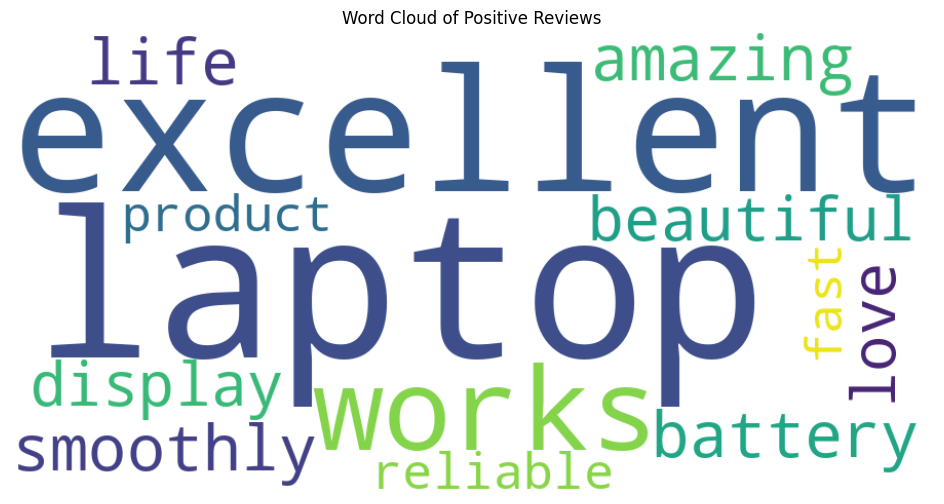

In [22]:

from wordcloud import WordCloud
from IPython.display import display

positive_reviews = [
    result["Review"]
    for result in results
    if result["Sentiment"] == "Positive"
]

positive_text = " ".join(positive_reviews)

if positive_text.strip():
    wordcloud = WordCloud(
        width=900,
        height=450,
        background_color="white",
        stopwords=stop_words,
        collocations=False
    ).generate(positive_text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()
else:
    print("No positive reviews available.")


In [23]:

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

tf.random.set_seed(42)
np.random.seed(42)

training_text = """
Technology changes the way people live and work.
Computers help people solve problems and organize information.
Artificial intelligence allows machines to learn patterns from data.
Machine learning improves predictions through experience.
Students use technology to learn new skills and explore ideas.
Teachers use digital tools to explain difficult concepts.
Scientific research benefits from faster computation and better data analysis.
Healthcare systems use computers to support doctors and patients.
Responsible technology should protect privacy and improve human lives.
Learning new technologies requires practice, patience, and curiosity.
People can use technology to communicate and share knowledge.
Innovation creates opportunities to build useful products.
The future depends on creative thinking and responsible development.
"""


In [24]:

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])

total_words = len(tokenizer.word_index) + 1

print("Vocabulary size:", total_words)
print("\nWord index:")
print(tokenizer.word_index)


Vocabulary size: 82

Word index:
{'and': 1, 'to': 2, 'technology': 3, 'use': 4, 'people': 5, 'the': 6, 'computers': 7, 'learn': 8, 'from': 9, 'data': 10, 'learning': 11, 'new': 12, 'responsible': 13, 'changes': 14, 'way': 15, 'live': 16, 'work': 17, 'help': 18, 'solve': 19, 'problems': 20, 'organize': 21, 'information': 22, 'artificial': 23, 'intelligence': 24, 'allows': 25, 'machines': 26, 'patterns': 27, 'machine': 28, 'improves': 29, 'predictions': 30, 'through': 31, 'experience': 32, 'students': 33, 'skills': 34, 'explore': 35, 'ideas': 36, 'teachers': 37, 'digital': 38, 'tools': 39, 'explain': 40, 'difficult': 41, 'concepts': 42, 'scientific': 43, 'research': 44, 'benefits': 45, 'faster': 46, 'computation': 47, 'better': 48, 'analysis': 49, 'healthcare': 50, 'systems': 51, 'support': 52, 'doctors': 53, 'patients': 54, 'should': 55, 'protect': 56, 'privacy': 57, 'improve': 58, 'human': 59, 'lives': 60, 'technologies': 61, 'requires': 62, 'practice': 63, 'patience': 64, 'curiosity':

In [25]:

input_sequences = []

for line in training_text.strip().split("\n"):
    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(2, len(token_list) + 1):
        input_sequences.append(token_list[:i])

max_sequence_len = max(len(seq) for seq in input_sequences)

padded_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding="pre"
)

X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Maximum sequence length:", max_sequence_len)


Input shape: (97, 9)
Target shape: (97,)
Maximum sequence length: 10


In [26]:

model = Sequential([
    Embedding(total_words, 32, input_length=max_sequence_len - 1),
    LSTM(64),
    Dense(total_words, activation="softmax")
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Training completed.


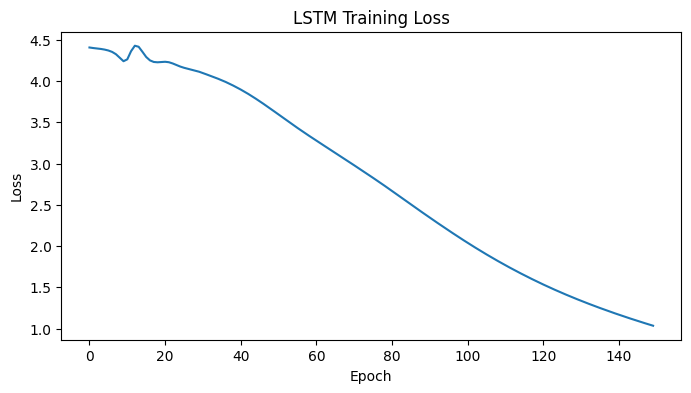

In [27]:

history = model.fit(
    X, y,
    epochs=150,
    verbose=0
)

print("Training completed.")

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"])
plt.title("LSTM Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()


In [28]:

def generate_text(seed_text, next_words=30):
    generated = seed_text.lower()

    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([generated])[0]

        if not token_list:
            break

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding="pre",
            truncating="pre"
        )

        predictions = model.predict(token_list, verbose=0)[0]
        predicted_id = int(np.argmax(predictions))

        if predicted_id == 0:
            break

        output_word = tokenizer.index_word.get(predicted_id)

        if output_word is None:
            break

        generated += " " + output_word

    return generated

seed_word = "technology"

generated_text = generate_text(seed_word, next_words=30)

# Display the generated text in approximately three lines
words = generated_text.split()
for i in range(0, len(words), 10):
    print(" ".join(words[i:i + 10]))


technology technology technology protect privacy and improve human lives lives
lives lives lives analysis analysis work and curiosity curiosity knowledge
data ideas analysis analysis analysis analysis and improve lives ideas
ideas


In [29]:

print("Seed: students")
print(generate_text("students", next_words=25))

print("\nSeed: artificial")
print(generate_text("artificial", next_words=25))


Seed: students
students use technology to to learn skills and explore ideas ideas analysis analysis analysis ideas analysis analysis and data knowledge data ideas analysis analysis analysis analysis

Seed: artificial
artificial use to to learn skills and patients data analysis analysis analysis analysis analysis analysis analysis and share knowledge data ideas analysis analysis analysis analysis analysis
